# Synthetic data processing and feature extraction

This notebook converts the normalized synthetic planner tables into an enrollment-level feature table for baseline risk testing. The processing rule is intentionally temporal: for each course offering, only records dated on or before the selected cutoff are aggregated. Final outcome fields are retained only as labels.

The 30-, 60-, and 90-day cutoffs represent increasingly informed decision points. Day 30 maximizes intervention lead time, day 60 offers more observed evidence, and day 90 is a later but still potentially actionable checkpoint. They are evaluation scenarios, not universal policy recommendations.

## Processing principles

- The modeling grain is one enrollment: one student-course-offering relationship.
- Parent tables are joined using explicit keys and validated relationships.
- Attendance, assessments, study sessions, topic state, availability, and wellbeing are filtered by event date before aggregation.
- Final grade, final result, and post-cutoff events are not predictors.
- Missing values remain missing where no event had yet occurred; model pipelines impute them after the train/test split.
- Identifiers are excluded from the predictor matrix because they identify records rather than generalizable learning signals.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / 'data' / 'raw' / 'synthetic'
from src.features.synthetic_features import build_cutoff_features, load_synthetic_tables

plt.style.use('seaborn-v0_8-whitegrid')
tables = load_synthetic_tables(DATA_DIR)
cutoffs = (30, 60, 90)
feature_sets = build_cutoff_features(DATA_DIR, cutoffs)
print({cutoff: frame.shape for cutoff, frame in feature_sets.items()})

{30: (12000, 51), 60: (12000, 51), 90: (12000, 51)}


## 1. Feature contract and target definition

The binary label is `risk_label = 1` when the simulated enrollment does not pass, including withdrawal or failure, and `0` when it passes. This label is created from the final outcome only. The feature table also retains `observation_cutoff_days` so that a downstream experiment cannot confuse a 30-day feature snapshot with a 90-day snapshot.

In [2]:
feature_columns = pd.DataFrame([
    {'feature_family': 'enrollment_context', 'examples': 'attempt_number, is_backlog, credits, difficulty, course_type', 'reason': 'Defines course workload and baseline academic context.'},
    {'feature_family': 'attendance', 'examples': 'attendance_pct_at_cutoff, attendance_absences', 'reason': 'Represents observed participation before the decision date.'},
    {'feature_family': 'assessment_progress', 'examples': 'assessment_mean_score, assessment_late_rate', 'reason': 'Summarizes assessed progress available by the cutoff.'},
    {'feature_family': 'study_behaviour', 'examples': 'session_completion_rate, active_study_minutes, distraction_minutes', 'reason': 'Represents planner-relevant engagement and schedule adherence.'},
    {'feature_family': 'topic_state', 'examples': 'mean_mastery_score, remaining_effort_hours', 'reason': 'Provides topic-level progress and workload signals.'},
    {'feature_family': 'time_and_wellbeing', 'examples': 'mean_available_hours, mean_sleep_hours, mean_screen_time_minutes', 'reason': 'Supports feasible and wellbeing-aware planning.'},
    {'feature_family': 'excluded_future_fields', 'examples': 'final_grade, result_status, academic_performance', 'reason': 'Excluded to prevent target leakage.'},
])
display(feature_columns)

# The next inventory is generated from the actual feature tables, rather than from a hand-written example list.
EXCLUDED_FROM_PREDICTORS = {
    'enrollment_id', 'student_id', 'offering_id', 'course_id', 'faculty_id',
    'department_id', 'program_id', 'risk_label', 'passed', 'withdrawn',
    'requires_retake', 'observation_cutoff_days', 'cutoff_date', 'start_date'
}
actual_feature_inventory = []
for cutoff, frame in feature_sets.items():
    selected_columns = [column for column in frame.columns if column not in EXCLUDED_FROM_PREDICTORS]
    for column in selected_columns:
        actual_feature_inventory.append({
            'cutoff_days': cutoff,
            'feature': column,
            'data_type': str(frame[column].dtype),
            'feature_role': 'numeric' if pd.api.types.is_numeric_dtype(frame[column]) else 'categorical'
        })
actual_feature_inventory_df = pd.DataFrame(actual_feature_inventory)
display(actual_feature_inventory_df.drop_duplicates('feature').drop(columns='cutoff_days').reset_index(drop=True))

for cutoff, frame in feature_sets.items():
    print(f'Cutoff {cutoff} days: {len(frame):,} enrollments, {frame.risk_label.mean() * 100:.2f}% risk labels')
    display(frame[['enrollment_id', 'student_id', 'offering_id', 'observation_cutoff_days', 'risk_label']].head(3))

,feature_family,examples,reason
0,enrollment_context,"attempt_number, is_backlog, credits, difficult...",Defines course workload and baseline academic ...
1,attendance,"attendance_pct_at_cutoff, attendance_absences",Represents observed participation before the d...
2,assessment_progress,"assessment_mean_score, assessment_late_rate",Summarizes assessed progress available by the ...
3,study_behaviour,"session_completion_rate, active_study_minutes,...",Represents planner-relevant engagement and sch...
4,topic_state,"mean_mastery_score, remaining_effort_hours",Provides topic-level progress and workload sig...
5,time_and_wellbeing,"mean_available_hours, mean_sleep_hours, mean_s...",Supports feasible and wellbeing-aware planning.
6,excluded_future_fields,"final_grade, result_status, academic_performance",Excluded to prevent target leakage.


,feature,data_type,feature_role
0,attempt_number,int64,numeric
1,is_backlog,bool,numeric
2,enrollment_status,object,categorical
3,enrollment_date,object,categorical
4,term_id,object,categorical
5,section,object,categorical
6,attendance_requirement_percent,float64,numeric
7,course_type,object,categorical
8,credits,int64,numeric
9,difficulty,object,categorical


Cutoff 30 days: 12,000 enrollments, 1.27% risk labels


,enrollment_id,student_id,offering_id,observation_cutoff_days,risk_label
0,ENR-STU0001-CSE101-TERM1,STU0001,CSE101-TERM1,30,0
1,ENR-STU0001-MAT101-TERM1,STU0001,MAT101-TERM1,30,0
2,ENR-STU0001-ECE101-TERM1,STU0001,ECE101-TERM1,30,0


Cutoff 60 days: 12,000 enrollments, 1.27% risk labels


,enrollment_id,student_id,offering_id,observation_cutoff_days,risk_label
0,ENR-STU0001-CSE101-TERM1,STU0001,CSE101-TERM1,60,0
1,ENR-STU0001-MAT101-TERM1,STU0001,MAT101-TERM1,60,0
2,ENR-STU0001-ECE101-TERM1,STU0001,ECE101-TERM1,60,0


Cutoff 90 days: 12,000 enrollments, 1.27% risk labels


,enrollment_id,student_id,offering_id,observation_cutoff_days,risk_label
0,ENR-STU0001-CSE101-TERM1,STU0001,CSE101-TERM1,90,0
1,ENR-STU0001-MAT101-TERM1,STU0001,MAT101-TERM1,90,0
2,ENR-STU0001-ECE101-TERM1,STU0001,ECE101-TERM1,90,0


The actual inventory is the predictor contract used by the baseline experiment. Features are retained when they are available by the decision date, represent a planner-relevant construct, and do not encode an identifier or a future outcome. This is a design-time rule; features are not selected because they happen to correlate with the simulated label in this particular sample.

## 2. Missingness and descriptive checks after aggregation

At an early cutoff, an enrollment may have no assessment attempt or no topic-state observation yet. That is informative availability, not permission to invent a zero score. The baseline notebook uses median/most-frequent imputation inside a scikit-learn pipeline fitted only on training students.

In [3]:
missing_rows = []
for cutoff, frame in feature_sets.items():
    for column in frame.columns:
        missing_rows.append({'cutoff_days': cutoff, 'feature': column, 'missing': int(frame[column].isna().sum()), 'missing_pct': frame[column].isna().mean() * 100})
missing = pd.DataFrame(missing_rows)
display(missing.query('missing > 0').sort_values(['cutoff_days', 'missing_pct'], ascending=[True, False]).head(30).round(2))

numeric_summary = []
for cutoff, frame in feature_sets.items():
    numeric = frame.select_dtypes(include='number').drop(columns=['risk_label'], errors='ignore')
    for column in numeric.columns:
        values = numeric[column].dropna()
        numeric_summary.append({'cutoff_days': cutoff, 'feature': column, 'mean': values.mean(), 'median': values.median(), 'std': values.std(), 'q1': values.quantile(.25), 'q3': values.quantile(.75)})
display(pd.DataFrame(numeric_summary).round(2).head(40))

,cutoff_days,feature,missing,missing_pct


,cutoff_days,feature,mean,median,std,q1,q3
0,30,attempt_number,1.01,1.00,0.11,1.00,1.00
1,30,attendance_requirement_percent,75.00,75.00,0.00,75.00,75.00
2,30,credits,3.58,4.00,0.64,3.00,4.00
3,30,estimated_effort_hours,68.00,71.00,12.41,63.00,76.50
4,30,observation_cutoff_days,30.00,30.00,0.00,30.00,30.00
5,30,attendance_classes_observed,4.58,5.00,0.49,4.00,5.00
6,30,attendance_absences,0.91,1.00,0.96,0.00,1.00
7,30,attendance_pct_at_cutoff,80.22,80.00,20.89,75.00,100.00
8,30,attendance_pct_mean,80.28,91.00,24.43,66.67,100.00
9,30,assessment_attempt_count,1.00,1.00,0.00,1.00,1.00


## 3. Effect of the observation window

As the cutoff increases, the feature table can contain more observed attendance, assessments, sessions, and wellbeing days. The following plots compare the observed evidence rather than claiming that more data is always better. A later cutoff may improve discrimination but reduces the time available for intervention.

,cutoff_days,mean_attendance,mean_assessments_observed,mean_planned_sessions,mean_sleep_hours
0,30,80.22,1.0,2.25,6.52
1,60,80.02,2.0,4.50,6.52
2,90,80.01,2.0,6.50,6.52


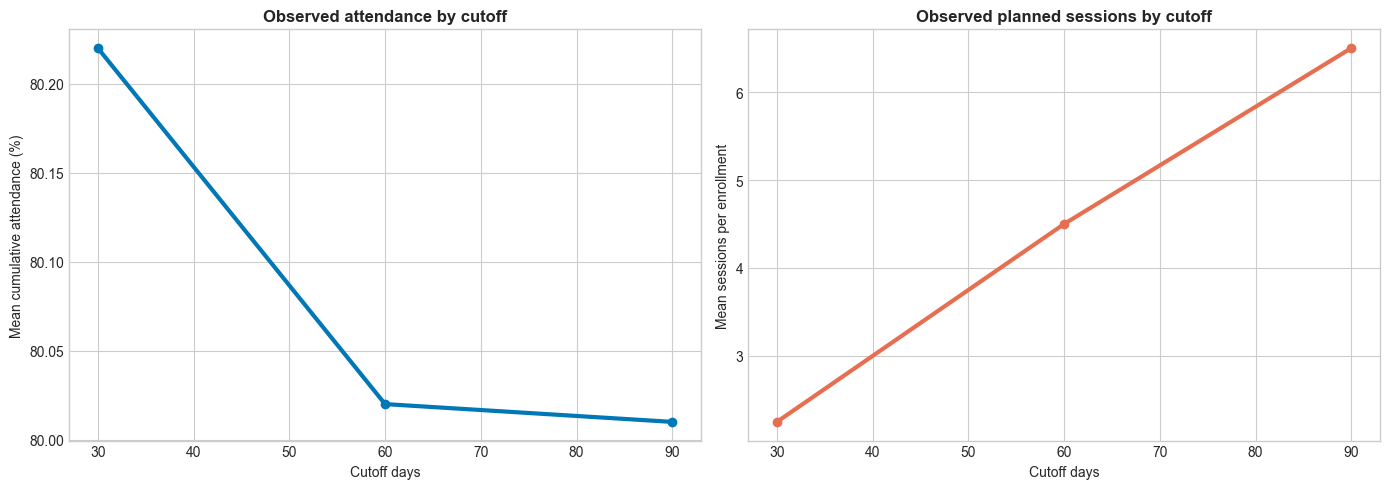

In [4]:
window_summary = pd.DataFrame([
    {'cutoff_days': cutoff, 'mean_attendance': frame['attendance_pct_at_cutoff'].mean(), 'mean_assessments_observed': frame['assessment_attempt_count'].mean(), 'mean_planned_sessions': frame['planned_sessions'].mean(), 'mean_sleep_hours': frame['mean_sleep_hours'].mean()}
    for cutoff, frame in feature_sets.items()
]).round(2)
display(window_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(window_summary['cutoff_days'], window_summary['mean_attendance'], marker='o', linewidth=3, color='#0077b6')
axes[0].set_title('Observed attendance by cutoff', weight='bold')
axes[0].set_xlabel('Cutoff days')
axes[0].set_ylabel('Mean cumulative attendance (%)')
axes[1].plot(window_summary['cutoff_days'], window_summary['mean_planned_sessions'], marker='o', linewidth=3, color='#e76f51')
axes[1].set_title('Observed planned sessions by cutoff', weight='bold')
axes[1].set_xlabel('Cutoff days')
axes[1].set_ylabel('Mean sessions per enrollment')
plt.tight_layout()
plt.show()

## 4. Processing conclusion

The reusable function `build_synthetic_features` is the processing contract used by the baseline notebook. It keeps the synthetic relational data separate from OULAD, preserves the enrollment grain, filters events before aggregation, and makes the cutoff explicit. The next notebook uses student-disjoint train/test splits so records from one student cannot appear in both partitions.